<a href="https://colab.research.google.com/github/skandanyal/ML-Lab-7th-sem/blob/main/mlLab8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import Libraries and Load Dataset

We will use the Breast Cancer Wisconsin dataset from scikit-learn for this binary classification task.

In [4]:
# Install kagglehub with pandas support
!pip install -q kagglehub[pandas-datasets]

In [5]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the training set from the Mobile Price Classification dataset
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "iabhishekofficial/mobile-price-classification",
  "train.csv"
)

# Separate features and multi-class target ('price_range')
X = df.drop(columns=['price_range'])
y = df['price_range']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"New Complex Dataset Loaded:")
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Classes to predict: {sorted(y.unique())}")

display(X.head())

/tmp/ipykernel_988/1158925783.py:7: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'mobile-price-classification' dataset.
New Complex Dataset Loaded:
Training set shape: (1600, 20)
Testing set shape: (400, 20)
Classes to predict: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (455, 30)
Testing set shape: (114, 30)


## 2. Model Training (Bagging & Boosting)

We will define, fit, and predict using:
- **Bagging**: Standard Bagging Classifier (with Decision Trees) and Random Forest.
- **Boosting**: AdaBoost and Gradient Boosting.

In [6]:
# Initialize models
models = {
    'Bagging (Decision Tree)': BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# Dictionary to store performance metrics
results = {}

# Train and evaluate each model for multi-class target
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted'),
        'Recall': recall_score(y_test, y_pred, average='weighted'),
        'F1-Score': f1_score(y_test, y_pred, average='weighted'),
        'ROC-AUC': roc_auc_score(y_test, y_prob, multi_class='ovr', average='weighted')
    }

# Convert results to DataFrame
df_results = pd.DataFrame(results).T
display(df_results)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Bagging (Decision Tree),0.8850,0.889247,0.8850,0.885491,0.987206
Random Forest,0.8925,0.896138,0.8925,0.893340,0.983616
AdaBoost,0.7325,0.730026,0.7325,0.730030,0.877904
Gradient Boosting,0.9050,0.906446,0.9050,0.905496,0.986098


## 3. Compare Performance Metrics

Let's visualize the metrics to easily compare how Bagging and Boosting algorithms perform relative to each other.

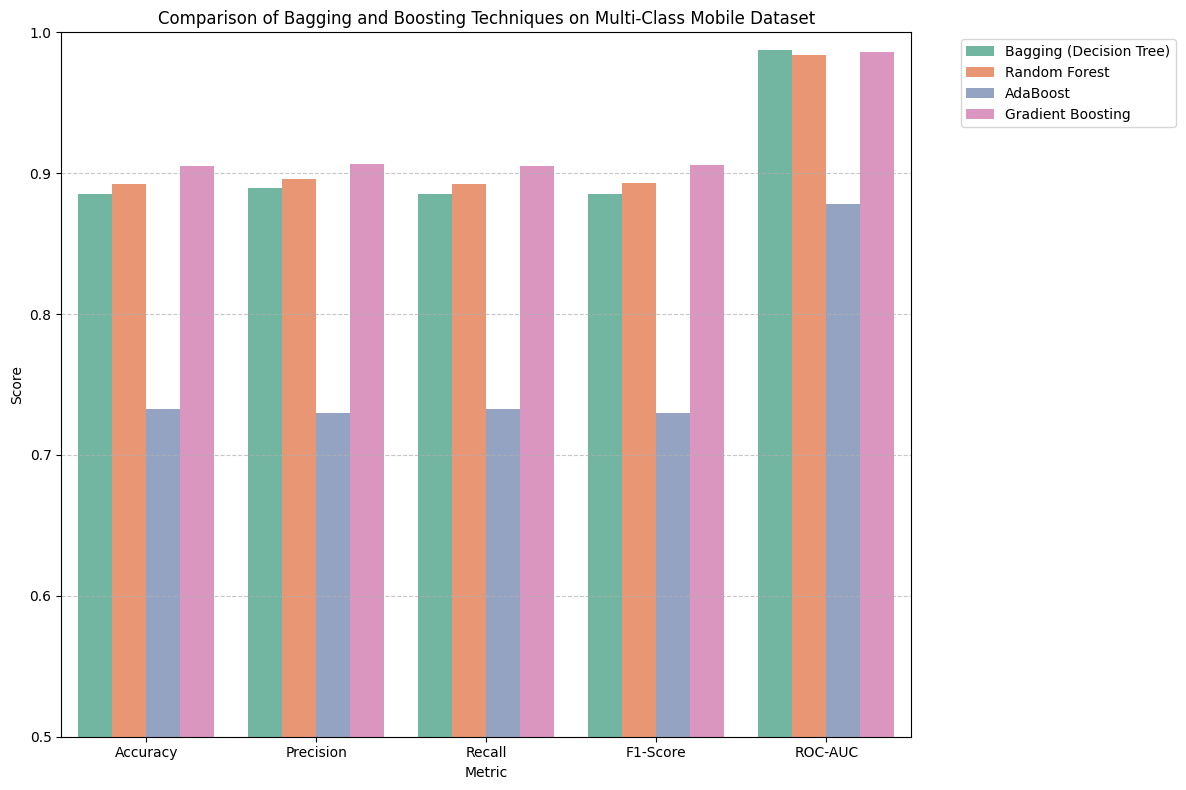

In [7]:
# Plot comparison
plt.figure(figsize=(12, 8))
df_melted = df_results.reset_index().melt(id_vars='index', var_name='Metric', value_name='Value')
df_melted.rename(columns={'index': 'Model'}, inplace=True)

sns.barplot(data=df_melted, x='Metric', y='Value', hue='Model', palette='Set2')
plt.title('Comparison of Bagging and Boosting Techniques on Multi-Class Mobile Dataset')
plt.ylabel('Score')
plt.ylim(0.5, 1.0) # Adjusted limits since multi-class classification is significantly harder
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()